# Computer Vision Graded Assigment


**Student Instructions:**
- Complete all four exercises
- Show your work using *code comments*
- You can use Google
- AI tools are not allowed (using them may result in failing the midterm)
- Make sure all code outputs are visible; otherwise, you may lose points
- `Rename the notebook using your full name before uploading it to Moodle for evaluation`

Good luck:)


## Exercise 1: Recurrent Neural Networks (35 points)

Predict the next-day closing price of Microsoft stock using one year of daily data.

*The quality of the prediction is not important — you are graded on data preparation, modeling steps, and correctness of implementation.*

- Handle missing values
- Scale features
- Create a sliding window
- Train an evaluate LSTM model

In [1]:
!pip install --upgrade pip

In [2]:
%pip install --upgrade yahooquery

In [3]:
from yahooquery import Ticker

tc = Ticker('MSFT')
msft = tc.history(start = '2023-01-01', end  = '2024-01-01')

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# I fixed random seeds so the results are reproducible
np.random.seed(42)
tf.random.set_seed(42)

# yahooquery returns a DataFrame with a MultiIndex (symbol, date) -> flatten it
df = msft.reset_index()
df["date"] = pd.to_datetime(df["date"], utc=True).dt.tz_localize(None).dt.normalize()
df = df.set_index("date").sort_index()

# Keeping only the numeric price/volume columns we need
features = ["open", "high", "low", "close", "volume"]
df = df[features]

print("Shape:", df.shape)
print(df.head())
print(df.describe())

Shape: (250, 5)
                  open        high         low       close    volume
date                                                                
2023-01-03  243.080002  245.750000  237.399994  239.580002  25740000
2023-01-04  232.279999  232.869995  225.960007  229.100006  50623400
2023-01-05  227.199997  227.550003  221.759995  222.309998  39585600
2023-01-06  223.000000  225.759995  219.350006  224.929993  43613600
2023-01-09  226.449997  231.240005  226.410004  227.119995  27369800
             open        high         low       close        volume
count  250.000000  250.000000  250.000000  250.000000  2.500000e+02
mean   313.701720  316.770681  310.811919  313.951001  2.767710e+07
std     41.055768   40.987979   40.872155   40.975858  1.063932e+07
min    223.000000  225.759995  219.350006  222.309998  1.017660e+07
25%    283.304993  285.207512  281.520012  282.994987  2.119620e+07
50%    324.869995  328.865005  321.589996  324.650009  2.505275e+07
75%    337.284988  340.88

### Handle missing values

Missing values before cleaning:
 open      0
high      0
low       0
close     0
volume    0
dtype: int64

Missing values after re-indexing to business days:
 open      9
high      9
low       9
close     9
volume    9
dtype: int64

Missing values after ffill/bfill:
 open      0
high      0
low       0
close     0
volume    0
dtype: int64
Final shape: (259, 5)


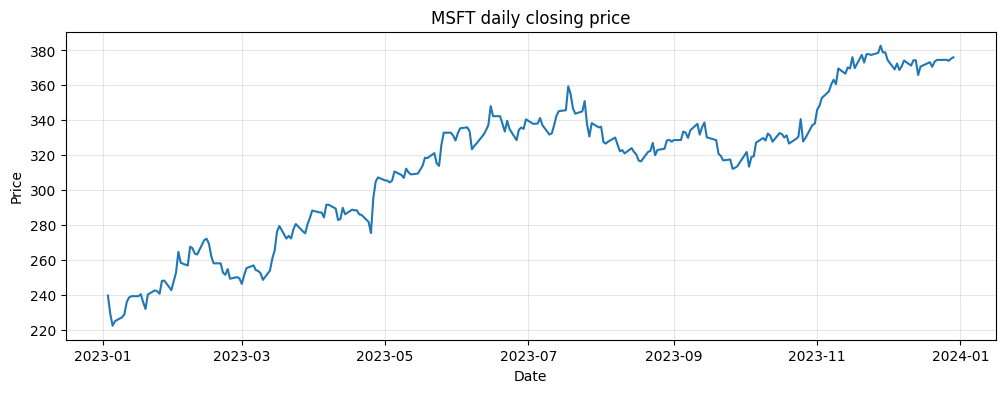

In [5]:
# I checked how many values are missing in every column
print("Missing values before cleaning:\n", df.isna().sum())

# Then removed duplicated dates (if the API returned any)
df = df[~df.index.duplicated(keep="first")]

# Making the calendar complete on business days so that gaps become visible as NaN
df = df.asfreq("B")
print("\nMissing values after re-indexing to business days:\n", df.isna().sum())

# Time series -> forward fill, then back fill for a possible gap at the start
df = df.ffill().bfill()

print("\nMissing values after ffill/bfill:\n", df.isna().sum())
print("Final shape:", df.shape)

# Visualising the closing price
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["close"])
plt.title("MSFT daily closing price")
plt.xlabel("Date"); plt.ylabel("Price")
plt.grid(alpha=0.3)
plt.show()

###Scale feautres

In [6]:
# Chronological split: first 80% train, last 20% test
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]
print("Train:", train_df.index.min().date(), "->", train_df.index.max().date(), len(train_df))
print("Test :", test_df.index.min().date(), "->", test_df.index.max().date(), len(test_df))

# Scaling all input features to [0, 1].
# The scaler is fitted inly on the training data to avoid data laekage from the future.
feature_scaler = MinMaxScaler()
train_scaled = feature_scaler.fit_transform(train_df[features])
test_scaled = feature_scaler.transform(test_df[features])

# A separate scaler for the target so we can easily invert predictions back to USD
target_scaler = MinMaxScaler()
target_scaler.fit(train_df[["close"]])

close_idx = features.index("close")  # position of the target column inside the feature matrix

Train: 2023-01-03 -> 2023-10-18 207
Test : 2023-10-19 -> 2023-12-29 52


### Create a sliding window

In [7]:
WINDOW = 20  # using the last 20 trading days to predict the next day's close

def create_windows(data, window, target_col):
    """Turn a 2-D array (time, features) into
    X: (samples, window, features) and y: (samples,) = close price of the next day."""
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i - window:i])
        y.append(data[i, target_col])
    return np.array(X), np.array(y)

X_train, y_train = create_windows(train_scaled, WINDOW, close_idx)

# For the test set, prepend the last WINDOW days of training date so that the first test day also has a full history window
test_with_history = np.vstack([train_scaled[-WINDOW:], test_scaled])
X_test, y_test = create_windows(test_with_history, WINDOW, close_idx)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test :", X_test.shape, " y_test :", y_test.shape)

X_train: (187, 20, 5)  y_train: (187,)
X_test : (52, 20, 5)  y_test : (52,)


### Train and evaluate the LSTM

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 17s 315ms/step - loss: 0.1625 - mae: 0.3741 - val_loss: 0.0086 - val_mae: 0.0710
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 0.0426 - mae: 0.1692 - val_loss: 0.0051 - val_mae: 0.0632
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - loss: 0.0322 - mae: 0.1397 - val_loss: 0.0060 - val_mae: 0.0656
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - loss: 0.0145 - mae: 0.0968 - val_loss: 0.0073 - val_mae: 0.0654
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - loss: 0.0200 - mae: 0.1056 - val_loss: 0.0046 - val_mae: 0.0613
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - loss: 0.0105 - mae: 0.0831 - val_loss: 0.0049 - val_mae: 0.0618
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0120 - mae: 0.0846 - val_loss: 0.0046 - val_mae: 0.0613
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - loss: 0.0104 - mae: 0.0813 - val_loss: 0.0046 - val_mae: 0.0614
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - 

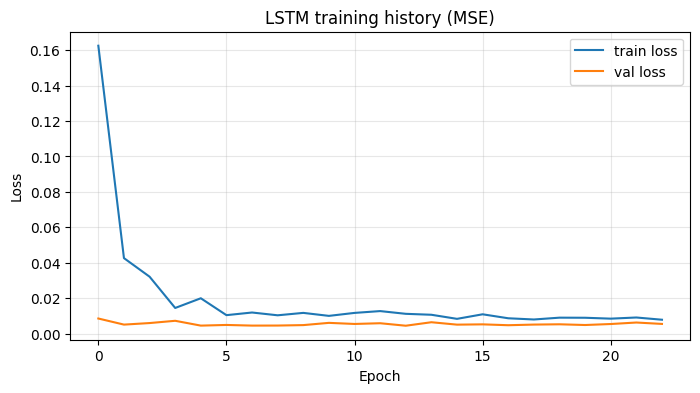

In [8]:
# Model: 2 stacked LSTM layers + dropout for regularisation + 1 output neuron
model = Sequential([
    Input(shape=(WINDOW, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

# Early stopping on a validation split
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

# Plot learning curves
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.title("LSTM training history (MSE)")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

LSTM  -> RMSE: 23.02 USD | MAE: 21.32 USD | MAPE: 5.77%
Naive -> RMSE: 4.46 USD


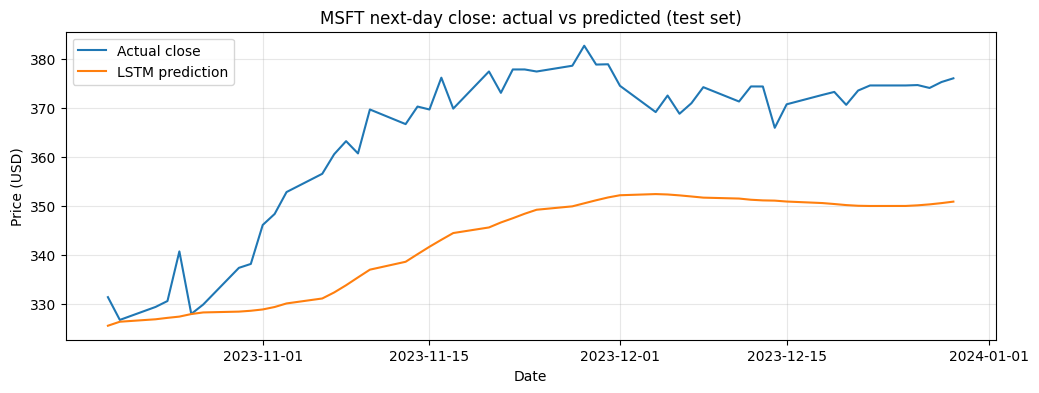

Last known close (2023-12-29): 376.04 USD
Predicted next-day close: 351.19 USD


In [9]:
# Evaluation on the test set
pred_scaled = model.predict(X_test, verbose=0)

# Convert predictions and true values back to USD
y_pred = target_scaler.inverse_transform(pred_scaled).ravel()
y_true = target_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Nayive baseline-to know whether the LSTM learned anything
naive_pred = test_with_history[WINDOW - 1:-1, close_idx]
naive_pred = target_scaler.inverse_transform(naive_pred.reshape(-1, 1)).ravel()
naive_rmse = np.sqrt(mean_squared_error(y_true, naive_pred))

print(f"LSTM  -> RMSE: {rmse:.2f} USD | MAE: {mae:.2f} USD | MAPE: {mape:.2f}%")
print(f"Naive -> RMSE: {naive_rmse:.2f} USD")

# Plot predictions vs actual prices
plt.figure(figsize=(12, 4))
plt.plot(test_df.index, y_true, label="Actual close")
plt.plot(test_df.index, y_pred, label="LSTM prediction")
plt.title("MSFT next-day close: actual vs predicted (test set)")
plt.xlabel("Date"); plt.ylabel("Price (USD)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Forecast the next trading day after the dataset ends
last_window = feature_scaler.transform(df[features].iloc[-WINDOW:])
next_scaled = model.predict(last_window[np.newaxis, ...], verbose=0)
next_close = target_scaler.inverse_transform(next_scaled)[0, 0]
print(f"Last known close ({df.index[-1].date()}): {df['close'].iloc[-1]:.2f} USD")
print(f"Predicted next-day close: {next_close:.2f} USD")

## Exercise 2 : NLP Transformers (15 points)

Analyze the sentiment of three customer reviews. Predict whether each review is positive or negative, display the confidence scores, and compare the results.

Input text:
- "The delivery was fast, and the product exceeded my expectations."
- "The quality was poor, and customer service was unhelpful."
- "The product is okay, but I expected something better." <br>


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,review,prediction,confidence,P(NEGATIVE),P(POSITIVE)
0,"The delivery was fast, and the product exceeded my expectations.",POSITIVE,0.9991,0.0009,0.9991
1,"The quality was poor, and customer service was unhelpful.",NEGATIVE,0.9998,0.9998,0.0002
2,"The product is okay, but I expected something better.",NEGATIVE,0.6848,0.6848,0.3152


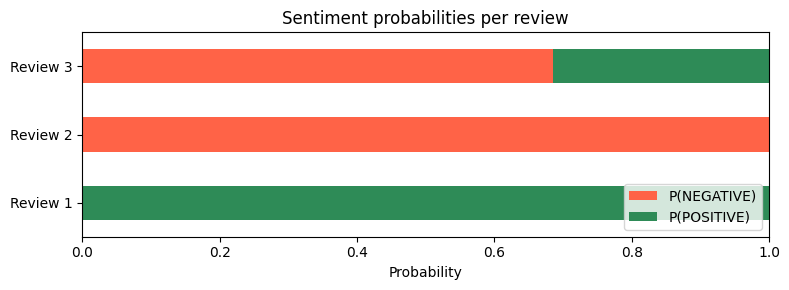

In [11]:
# your code here
model_name = "distilbert-base-uncased-finetuned-sst-2-english"

import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Loading the tokenizer and the model fine-tuned on SST-2
tokenizer = AutoTokenizer.from_pretrained(model_name)
sentiment_model = AutoModelForSequenceClassification.from_pretrained(model_name)
sentiment_model.eval()

reviews = [
    "The delivery was fast, and the product exceeded my expectations.",
    "The quality was poor, and customer service was unhelpful.",
    "The product is okay, but I expected something better.",
]
inputs = tokenizer(reviews, padding=True, truncation=True, return_tensors="pt")

# forward pass without gradients -> logits -> softmax probabilities
with torch.no_grad():
    logits = sentiment_model(**inputs).logits
probs = torch.softmax(logits, dim=-1).numpy()

labels = sentiment_model.config.id2label   # {0: 'negative', 1: 'positive'}

# Collect results in a table: predicted label, its confidence and both class probabilities
results = pd.DataFrame({
    "review": reviews,
    "prediction": [labels[int(p.argmax())] for p in probs],
    "confidence": probs.max(axis=1).round(4),
    "P(NEGATIVE)": probs[:, 0].round(4),
    "P(POSITIVE)": probs[:, 1].round(4),
})
pd.set_option("display.max_colwidth", None)
display(results)

# visual comparison of the class probabilities
results.set_index(pd.Index(["Review 1", "Review 2", "Review 3"]))[["P(NEGATIVE)", "P(POSITIVE)"]] \
    .plot(kind="barh", stacked=True, color=["tomato", "seagreen"], figsize=(8, 3))
plt.title("Sentiment probabilities per review")
plt.xlabel("Probability"); plt.xlim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Comparison of the results**

- Review 1 has clearly positive words → the model predicts positive with very high confidence.
- Review 2 has clearly negative words → negative with very high confidence.
- Review 3 leans negative because of the "but I expected something better" part, which reflects disappointment. This shows a limitation of binary sentiment models: they cannot output "neutral", and a high confidence score does not always mean the text is strongly emotional.

## Exercise 3: Vision-Language Models (15 points)

Use a pretrained CLIP model to identify which text description best matches a given image. You must use the provided image and candidate descriptions.

In [12]:
from google.colab import files
from IPython.display import Image

uploaded = files.upload()

Saving image.jpeg to image (4).jpeg


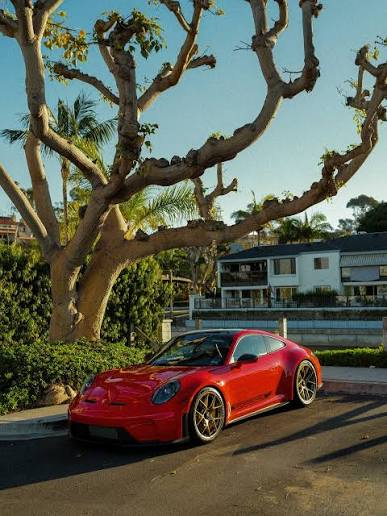

In [13]:
Image('image.jpeg')

In [14]:
image_path = 'image.jpeg'
candidate_descriptions = [
    "A red car driving on a road",
    "A blue bicycle near a tree",
    "A bus parked at a station"
]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

A red car driving on a road         similarity= 25.95  probability=0.9999
A blue bicycle near a tree          similarity= 14.29  probability=0.0000
A bus parked at a station           similarity= 16.33  probability=0.0001

Best matching description: 'A red car driving on a road' (99.99%)


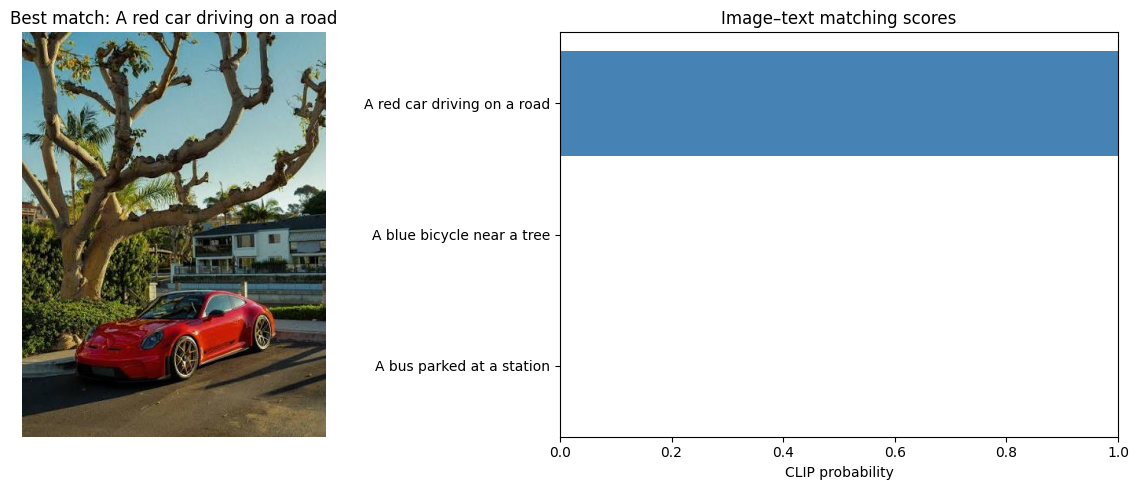

In [15]:
# your code here
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

# Loading a pretrained CLIP model (image encoder + text encoder trained jointly)
clip_name = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_name)
clip_processor = CLIPProcessor.from_pretrained(clip_name)
clip_model.eval()

# Loading the image
image = Image.open(image_path).convert("RGB")

# Preprocess image and all candidate texts together
clip_inputs = clip_processor(text=candidate_descriptions, images=image,
                             return_tensors="pt", padding=True)

# logits_per_image = scaled cosine similarity between the image and every text
with torch.no_grad():
    outputs = clip_model(**clip_inputs)
logits = outputs.logits_per_image
clip_probs = logits.softmax(dim=1)[0]      # convert to probabilitis over the candidates

# Printing the score of every description
for desc, logit, p in zip(candidate_descriptions, logits[0], clip_probs):
    print(f"{desc:<35} similarity={logit.item():6.2f}  probability={p.item():.4f}")

best_idx = int(clip_probs.argmax())
print(f"\nBest matching description: '{candidate_descriptions[best_idx]}' "
      f"({clip_probs[best_idx].item():.2%})")

# Show the image together with the scores
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].imshow(image); axes[0].axis("off")
axes[0].set_title(f"Best match: {candidate_descriptions[best_idx]}")
axes[1].barh(candidate_descriptions, clip_probs.numpy(), color="steelblue")
axes[1].set_xlim(0, 1); axes[1].invert_yaxis()
axes[1].set_xlabel("CLIP probability"); axes[1].set_title("Image–text matching scores")
plt.tight_layout(); plt.show()

## Exercise 4: Retrieval-Augmented Generation (35 points)
Build a small RAG pipeline that answers a question using a provided txt.

- Split the document into chunks using chunking
- Generate embeddings for the text chunks
- Store embeddings in a vector database
- Implement semantic search to retrieve the top-k relevant chunks
- Connect the retrieved context to a language model
- Test the RAG pipeline with different questions and evaluate the answers

In [16]:
from google.colab import files
from IPython.display import Image

uploaded = files.upload()

Saving university_student_services.txt to university_student_services (2).txt


In [17]:
file_path = "university_student_services.txt"

with open(file_path, "r", encoding="utf-8") as file:
    text = file.read()

In [18]:
print(text)

STUDENT SERVICES AND UNIVERSITY LIFE

LIBRARY SERVICES
----------------
The university library is open Monday through Friday from 9:00 AM to 7:00 PM and on Saturdays from 10:00 AM to 3:00 PM. It is closed on Sundays and public holidays.

Students can borrow up to five books at a time. The standard borrowing period is 14 days. Books may be renewed once if no other student has reserved them. Reference books must be used inside the library and cannot be borrowed.

Students must present their university ID card to borrow books. Overdue books may result in temporary borrowing restrictions. Students should contact library staff if a borrowed item is lost or damaged.

ACADEMIC ADVISING
-----------------
The Academic Advising Office helps students plan their course schedules, understand degree requirements, and explore academic support options.

Advising appointments are available Monday through Thursday from 10:00 AM to 4:00 PM. Students can book an appointment through the university student 

In [19]:
# Installing the libraries for the RAG pipeline
%pip install -q sentence-transformers chromadb

### Chunking

In [20]:
import re

def chunk_document(text, max_chars=500, overlap=100):
    """Section-aware chunking:
    1. split the document at section headings (a line followed by a '-----' underline),
    2. split each section into paragraphs,
    3. merge paragraphs into chunks of at most `max_chars`, keeping `overlap` characters
       from the previous chunk so that context is not lost at the borders.
    Every chunk is prefixed with its section title, which helps retrieval."""
    # Split into title and body using the '---' underlines
    parts = re.split(r"\n([A-Z][A-Z &]+)\n-+\n", text)
    sections = []
    for i in range(1, len(parts), 2):
        sections.append((parts[i].strip(), parts[i + 1].strip()))

    chunks = []
    for title, body in sections:
        paragraphs = [p.strip() for p in body.split("\n\n") if p.strip()]
        current = ""
        for para in paragraphs:
            if current and len(current) + len(para) + 1 > max_chars:
                chunks.append({"section": title, "text": f"{title}: {current.strip()}"})
                current = current[-overlap:] + " " + para   # sliding overlap
            else:
                current = (current + " " + para).strip()
        if current:
            chunks.append({"section": title, "text": f"{title}: {current.strip()}"})
    return chunks

chunks = chunk_document(text, max_chars=500, overlap=100)
print(f"Number of chunks: {len(chunks)}\n")
for i, c in enumerate(chunks[:4]):
    print(f"--- chunk {i} ({len(c['text'])} chars) ---\n{c['text']}\n")

Number of chunks: 19

--- chunk 0 (409 chars) ---
LIBRARY SERVICES: The university library is open Monday through Friday from 9:00 AM to 7:00 PM and on Saturdays from 10:00 AM to 3:00 PM. It is closed on Sundays and public holidays. Students can borrow up to five books at a time. The standard borrowing period is 14 days. Books may be renewed once if no other student has reserved them. Reference books must be used inside the library and cannot be borrowed.

--- chunk 1 (321 chars) ---
LIBRARY SERVICES: r student has reserved them. Reference books must be used inside the library and cannot be borrowed. Students must present their university ID card to borrow books. Overdue books may result in temporary borrowing restrictions. Students should contact library staff if a borrowed item is lost or damaged.

--- chunk 2 (365 chars) ---
ACADEMIC ADVISING: The Academic Advising Office helps students plan their course schedules, understand degree requirements, and explore academic support options

### Embeddings and vector database

In [21]:
from sentence_transformers import SentenceTransformer
import chromadb

# embedding model
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

chunk_texts = [c["text"] for c in chunks]
chunk_embeddings = embedder.encode(chunk_texts, normalize_embeddings=True, show_progress_bar=True)
print("Embedding matrix shape:", chunk_embeddings.shape)

# Creating an in-memory Chroma vector database with cosine distance
chroma_client = chromadb.Client()
try:
    chroma_client.delete_collection("student_services")
except Exception:
    pass
collection = chroma_client.create_collection(name="student_services",
                                             metadata={"hnsw:space": "cosine"})

# Storing the chunks, their embeddings and metadata
collection.add(
    ids=[f"chunk_{i}" for i in range(len(chunks))],
    documents=chunk_texts,
    embeddings=chunk_embeddings.tolist(),
    metadatas=[{"section": c["section"]} for c in chunks],
)
print("Documents stored in the vector DB:", collection.count())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding matrix shape: (19, 384)
Documents stored in the vector DB: 19


### Semantic search (top-k retrieval)

In [22]:
def retrieve(query, k=3):
    """Embed the query and return the k most similar chunks from the vector DB."""
    q_emb = embedder.encode([query], normalize_embeddings=True).tolist()
    res = collection.query(query_embeddings=q_emb, n_results=k)
    hits = []
    for doc, meta, dist in zip(res["documents"][0], res["metadatas"][0], res["distances"][0]):
        hits.append({"section": meta["section"], "text": doc, "similarity": 1 - dist})
    return hits

# Quick test of the retriever
for h in retrieve("When is the library open on weekends?", k=3):
    print(f"[{h['similarity']:.3f}] {h['section']}: {h['text'][:110]}...")

[0.722] LIBRARY SERVICES: LIBRARY SERVICES: The university library is open Monday through Friday from 9:00 AM to 7:00 PM and on Saturday...
[0.461] GENERAL INFORMATION: GENERAL INFORMATION: Office hours and procedures may change during holidays or special university events. Stud...
[0.339] LIBRARY SERVICES: LIBRARY SERVICES: r student has reserved them. Reference books must be used inside the library and cannot be b...


### Connect the retrieved context to a language model

In [23]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

llm_name = "google/flan-t5-large"
llm_tokenizer = AutoTokenizer.from_pretrained(llm_name)
llm = AutoModelForSeq2SeqLM.from_pretrained(llm_name)
device = "cuda" if torch.cuda.is_available() else "cpu"
llm.to(device).eval()

def build_prompt(question, contexts):
    """Put the retrieved chunks into the prompt and instruct the model to answer only from them."""
    context_block = "\n\n".join(f"[{i+1}] {c['text']}" for i, c in enumerate(contexts))
    return (
        "Answer the question using only the context below. "
        "If the answer is not in the context, say \"I don't know based on the document.\"\n\n"
        f"Context:\n{context_block}\n\n"
        f"Question: {question}\nAnswer:"
    )

def rag_answer(question, k=3, min_similarity=0.25, verbose=True):
    contexts = retrieve(question, k=k)
    # If even the best chunk is weakly related, do not leting the LLM guess
    if contexts[0]["similarity"] < min_similarity:
        answer = "I don't know based on the document."
    else:
        prompt = build_prompt(question, contexts)
        inputs = llm_tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024).to(device)
        with torch.no_grad():
            out = llm.generate(**inputs, max_new_tokens=80, num_beams=4)
        answer = llm_tokenizer.decode(out[0], skip_special_tokens=True)
    if verbose:
        print(f"Q: {question}")
        print("Retrieved:", [f"{c['section']} ({c['similarity']:.2f})" for c in contexts])
        print(f"A: {answer}\n")
    return answer, contexts

_ = rag_answer("How many books can a student borrow at a time?")

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Q: How many books can a student borrow at a time?
Retrieved: ['LIBRARY SERVICES (0.56)', 'LIBRARY SERVICES (0.51)', 'IT HELP DESK (0.28)']
A: Students can borrow up to five books at a time. The standard borrowing period is 14 days. Books may be renewed once if no other student has reserved them. Reference books must be used inside the library and cannot be borrowed. Students must present their university ID card to borrow books. Overdue books may result in temporary borrowing restrictions. Students should contact library staff if a borrowed item



### Test the RAG pipeline with different questions and evaluate the answers

In [24]:
import pandas as pd

# Test set: question, section that should be retrieved, keywords the correct answer must contain
test_cases = [
    {"q": "What are the library opening hours on Saturday?",
     "section": "LIBRARY SERVICES", "keywords": ["10", "3"]},
    {"q": "How long can I keep a borrowed book?",
     "section": "LIBRARY SERVICES", "keywords": ["14"]},
    {"q": "Which days can I book an academic advising appointment?",
     "section": "ACADEMIC ADVISING", "keywords": ["monday", "thursday"]},
    {"q": "Who should I contact if the student portal is not working?",
     "section": "COURSE REGISTRATION", "keywords": ["it help desk"]},
    {"q": "Who can tell me the status of my scholarship application?",
     "section": "SCHOLARSHIPS AND FINANCIAL AID", "keywords": ["financial aid"]},
    {"q": "Can I use my smartwatch during an exam?",
     "section": "EXAMINATION RULES", "keywords": ["instructor"]},
    {"q": "Does a parking permit guarantee me a parking space?",
     "section": "CAMPUS TRANSPORTATION AND PARKING", "keywords": ["no"]},
    {"q": "How do I start a new student club?",
     "section": "STUDENT CLUBS AND EVENTS", "keywords": ["student affairs"]},
    {"q": "How much does the cafeteria lunch cost?",
     "section": None, "keywords": ["don't know"]},
]

rows = []
for tc in test_cases:
    answer, ctx = rag_answer(tc["q"], k=3)
    retrieved_sections = [c["section"] for c in ctx]
    retrieval_hit = True if tc["section"] is None else tc["section"] in retrieved_sections
    answer_ok = all(kw in answer.lower() for kw in tc["keywords"])
    rows.append({"question": tc["q"], "answer": answer,
                 "top_section": retrieved_sections[0],
                 "retrieval_hit@3": retrieval_hit, "answer_correct": answer_ok})

eval_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
display(eval_df)

print(f"Retrieval Hit@3 : {eval_df['retrieval_hit@3'].mean():.0%}")
print(f"Answer accuracy : {eval_df['answer_correct'].mean():.0%}")

Q: What are the library opening hours on Saturday?
Retrieved: ['LIBRARY SERVICES (0.70)', 'GENERAL INFORMATION (0.44)', 'LIBRARY SERVICES (0.32)']
A: 10:00 AM to 3:00 PM

Q: How long can I keep a borrowed book?
Retrieved: ['LIBRARY SERVICES (0.51)', 'LIBRARY SERVICES (0.48)', 'EXAMINATION RULES (0.23)']
A: 14 days

Q: Which days can I book an academic advising appointment?
Retrieved: ['ACADEMIC ADVISING (0.78)', 'ACADEMIC ADVISING (0.59)', 'GENERAL INFORMATION (0.46)']
A: Monday through Thursday

Q: Who should I contact if the student portal is not working?
Retrieved: ['IT HELP DESK (0.56)', 'COURSE REGISTRATION (0.47)', 'CONTACT DIRECTORY (0.44)']
A: IT Help Desk

Q: Who can tell me the status of my scholarship application?
Retrieved: ['SCHOLARSHIPS AND FINANCIAL AID (0.69)', 'SCHOLARSHIPS AND FINANCIAL AID (0.65)', 'CONTACT DIRECTORY (0.39)']
A: Financial Aid Office

Q: Can I use my smartwatch during an exam?
Retrieved: ['EXAMINATION RULES (0.60)', 'EXAMINATION RULES (0.59)', 'EXAMIN

,question,answer,top_section,retrieval_hit@3,answer_correct
0,What are the library opening hours on Saturday?,10:00 AM to 3:00 PM,LIBRARY SERVICES,True,True
1,How long can I keep a borrowed book?,14 days,LIBRARY SERVICES,True,True
2,Which days can I book an academic advising appointment?,Monday through Thursday,ACADEMIC ADVISING,True,True
3,Who should I contact if the student portal is not working?,IT Help Desk,IT HELP DESK,True,True
4,Who can tell me the status of my scholarship application?,Financial Aid Office,SCHOLARSHIPS AND FINANCIAL AID,True,True
5,Can I use my smartwatch during an exam?,I don't know based on the document,EXAMINATION RULES,True,False
6,Does a parking permit guarantee me a parking space?,A permit does not guarantee that a parking space will be available,CAMPUS TRANSPORTATION AND PARKING,True,True
7,How do I start a new student club?,contact the Student Affairs Office,STUDENT CLUBS AND EVENTS,True,True
8,How much does the cafeteria lunch cost?,I don't know based on the document.,LIBRARY SERVICES,True,True


Retrieval Hit@3 : 100%
Answer accuracy : 89%
